In [1]:
# Import library yang dibutuhkan
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

# Memuat dataset California Housing
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# Menampilkan 5 baris pertama
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Menampilkan jumlah baris dan kolom
print("Jumlah baris dan kolom:", df.shape)

# Melihat informasi dataset
df.info()

# Mengecek missing values
print("\nJumlah missing values setiap kolom:")
print(df.isnull().sum())

# Mengecek data duplikat
print("\nJumlah data duplikat:", df.duplicated().sum())

# Statistik deskriptif
df.describe()


Jumlah baris dan kolom: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Jumlah missing values setiap kolom:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Jumlah data duplikat: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


### A2. Eksplorasi dan Visualisasi Data

Eksplorasi data dilakukan untuk memahami distribusi variabel target, hubungan antarfitur, serta hubungan fitur dengan variabel target `MedHouseVal`. Visualisasi yang digunakan meliputi histogram, heatmap korelasi, dan scatter plot.

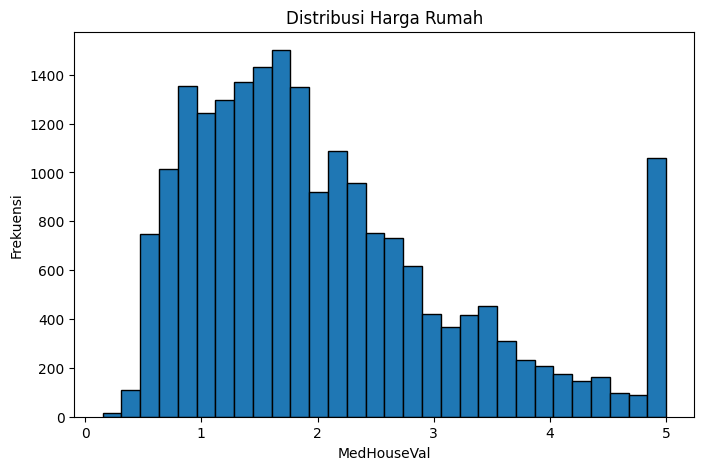

In [3]:
# Visualisasi 1: Histogram variabel target
plt.figure(figsize=(8, 5))
plt.hist(df['MedHouseVal'], bins=30, edgecolor='black')
plt.title('Distribusi Harga Rumah')
plt.xlabel('MedHouseVal')
plt.ylabel('Frekuensi')
plt.show()

**Interpretasi Visualisasi 1: Histogram**

Histogram menunjukkan distribusi nilai `MedHouseVal` yang sebagian besar berada pada kisaran 0,5 hingga 2,5. Distribusi cenderung miring ke kanan (*right-skewed*), dengan sebagian data memiliki nilai yang lebih tinggi. Terlihat juga penumpukan data pada nilai 5,0 yang menunjukkan adanya batas atas pada variabel target.

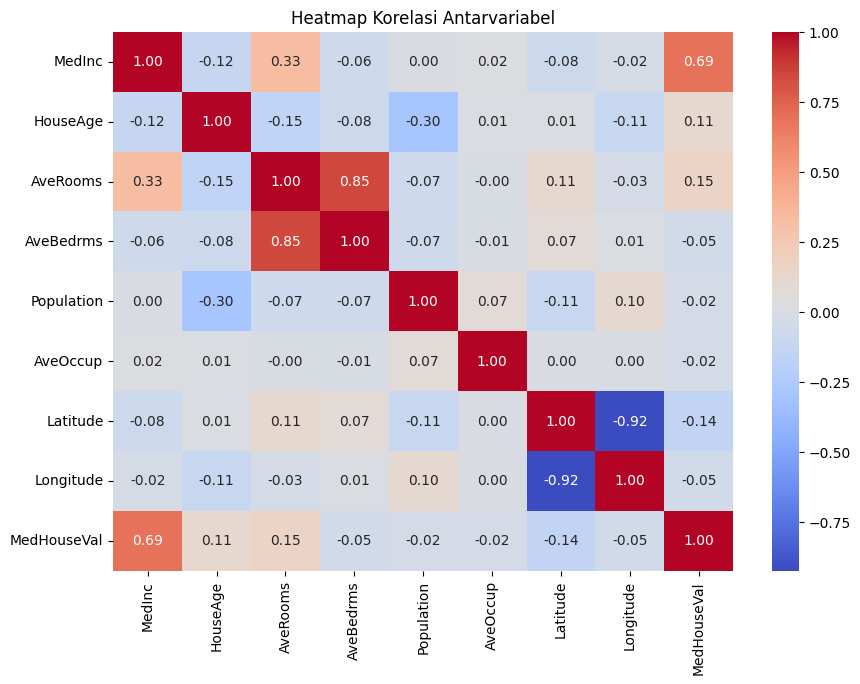

In [4]:
# Visualisasi 2: Heatmap korelasi
plt.figure(figsize=(10, 7))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Heatmap Korelasi Antarvariabel')
plt.show()

**Interpretasi Visualisasi 2: Heatmap Korelasi**

Heatmap menunjukkan bahwa fitur `MedInc` memiliki korelasi positif paling kuat dengan target `MedHouseVal`, yaitu sebesar 0,69. Artinya, semakin tinggi pendapatan median, harga median rumah cenderung semakin tinggi. Fitur `AveRooms` memiliki korelasi positif sebesar 0,15, sedangkan `Latitude` memiliki korelasi negatif sebesar -0,14. Selain itu, `AveRooms` dan `AveBedrms` memiliki korelasi kuat sebesar 0,85, sementara `Latitude` dan `Longitude` memiliki korelasi negatif kuat sebesar -0,92.

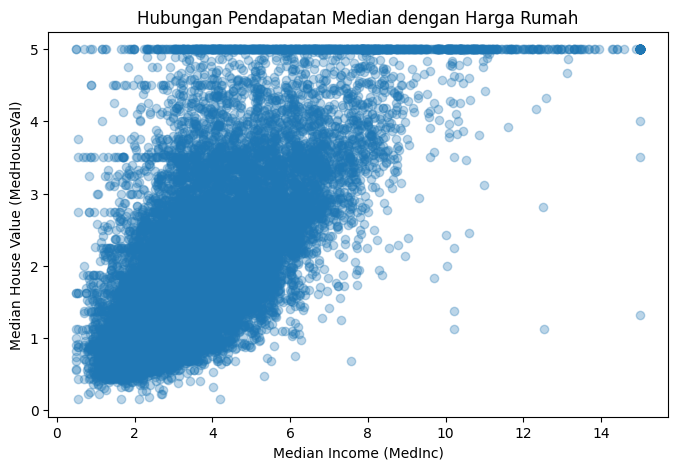

In [5]:
# Visualisasi 3: Hubungan pendapatan median dengan harga rumah
plt.figure(figsize=(8, 5))

plt.scatter(
    df['MedInc'],
    df['MedHouseVal'],
    alpha=0.3
)

plt.title('Hubungan Pendapatan Median dengan Harga Rumah')
plt.xlabel('Median Income (MedInc)')
plt.ylabel('Median House Value (MedHouseVal)')
plt.show()

**Interpretasi Visualisasi 3: Scatter Plot**

Scatter plot menunjukkan adanya hubungan positif antara `MedInc` (pendapatan median) dan `MedHouseVal` (nilai median rumah). Secara umum, semakin tinggi pendapatan median, nilai median rumah cenderung meningkat. Namun, titik data tersebar cukup luas sehingga pendapatan bukan satu-satunya faktor yang memengaruhi harga rumah. Terlihat juga penumpukan nilai target pada angka 5,0 yang menunjukkan adanya batas atas pada dataset.

### A3. Preprocessing

Preprocessing dilakukan untuk memeriksa missing values, data duplikat, dan outlier. Missing values dan data duplikat diperiksa terlebih dahulu. Outlier diperiksa menggunakan metode Interquartile Range (IQR). Seluruh fitur pada dataset ini bertipe numerik, sehingga encoding tidak diperlukan. Scaling akan dipertimbangkan sesuai kebutuhan model.

In [6]:
# Memeriksa missing values dan data duplikat
print("Missing values:", df.isnull().sum().sum())
print("Data duplikat:", df.duplicated().sum())

# Memeriksa outlier menggunakan metode IQR
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

outlier_count = (
    (df < (Q1 - 1.5 * IQR)) |
    (df > (Q3 + 1.5 * IQR))
).sum()

print("\nJumlah outlier pada setiap kolom:")
print(outlier_count)

Missing values: 0
Data duplikat: 0

Jumlah outlier pada setiap kolom:
MedInc          681
HouseAge          0
AveRooms        511
AveBedrms      1424
Population     1196
AveOccup        711
Latitude          0
Longitude         0
MedHouseVal    1071
dtype: int64


**Penanganan Outlier**

Pemeriksaan dengan metode Interquartile Range (IQR) menemukan outlier pada beberapa fitur numerik dan variabel target. Outlier tidak langsung dihapus karena dapat merepresentasikan kondisi nyata dalam dataset. Data asli dipertahankan agar informasi tidak hilang. Encoding tidak diperlukan karena seluruh fitur bertipe numerik, sedangkan scaling akan dilakukan menggunakan StandardScaler setelah pembagian data.

### A4. Pemilihan Fitur

Variabel target yang digunakan adalah `MedHouseVal`. Fitur prediktor yang dipilih adalah `MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, dan `Longitude`. Pemilihan ini didasarkan pada analisis korelasi dan pertimbangan bahwa setiap fitur dapat memberikan informasi tambahan dalam memprediksi nilai rumah. Korelasi tinggi antara `AveRooms` dan `AveBedrms`, serta antara `Latitude` dan `Longitude`, menjadi catatan untuk analisis multikolinearitas lebih lanjut.

In [7]:
# Memisahkan fitur dan variabel target
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# Menampilkan fitur yang dipilih
print("Fitur yang digunakan:")
print(X.columns.tolist())

print("\nJumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Fitur yang digunakan:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Jumlah fitur: 8
Jumlah target: 20640


### A5. Pembagian Data

Dataset dibagi menjadi 80% data latih dan 20% data uji menggunakan `train_test_split`. Data latih digunakan untuk membangun model, sedangkan data uji digunakan untuk mengevaluasi kemampuan model pada data yang belum pernah dilihat. Parameter `random_state=42` digunakan agar pembagian data dapat direproduksi.

In [8]:
from sklearn.model_selection import train_test_split

# Membagi data dengan rasio 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])
print("Bentuk X_train:", X_train.shape)
print("Bentuk X_test:", X_test.shape)

Jumlah data latih: 16512
Jumlah data uji: 4128
Bentuk X_train: (16512, 8)
Bentuk X_test: (4128, 8)


### A6. Pemodelan Linear Regression

Model Linear Regression digunakan untuk memprediksi nilai median rumah (`MedHouseVal`) berdasarkan delapan fitur yang telah dipilih. Model dilatih menggunakan data latih. Koefisien dan intercept ditampilkan untuk memahami hubungan setiap fitur dengan hasil prediksi.

In [9]:
from sklearn.linear_model import LinearRegression

# Membuat dan melatih model
model = LinearRegression()
model.fit(X_train, y_train)

# Menampilkan intercept
print("Intercept:", model.intercept_)

# Menampilkan koefisien setiap fitur
koefisien = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model.coef_
})

print("\nKoefisien setiap fitur:")
print(koefisien)

Intercept: -37.02327770606409

Koefisien setiap fitur:
        Fitur  Koefisien
0      MedInc   0.448675
1    HouseAge   0.009724
2    AveRooms  -0.123323
3   AveBedrms   0.783145
4  Population  -0.000002
5    AveOccup  -0.003526
6    Latitude  -0.419792
7   Longitude  -0.433708


### A7. Evaluasi Model

Evaluasi dilakukan menggunakan Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), dan R-squared (R²). Evaluasi dilakukan pada data latih dan data uji untuk mengetahui tingkat kesalahan prediksi serta kemampuan model menjelaskan variasi nilai target.

In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Membuat prediksi
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Fungsi evaluasi
def evaluasi_model(y_asli, y_prediksi, nama_data):
    mae = mean_absolute_error(y_asli, y_prediksi)
    mse = mean_squared_error(y_asli, y_prediksi)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_asli, y_prediksi)

    print(f"\nEvaluasi {nama_data}:")
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R-squared:", r2)

# Evaluasi data latih dan data uji
evaluasi_model(y_train, y_train_pred, "Data Latih")
evaluasi_model(y_test, y_test_pred, "Data Uji")



Evaluasi Data Latih:
MAE: 0.5286283596581922
MSE: 0.5179331255246699
RMSE: 0.7196757085831575
R-squared: 0.6125511913966952

Evaluasi Data Uji:
MAE: 0.5332001304956553
MSE: 0.5558915986952444
RMSE: 0.7455813830127764
R-squared: 0.5757877060324508


**Interpretasi Hasil Evaluasi**

Hasil evaluasi menunjukkan bahwa model memperoleh MAE sebesar 0,5286 dan R-squared sebesar 0,6126 pada data latih. Pada data uji, MAE sebesar 0,5332 dan R-squared sebesar 0,5758. Nilai MAE dan RMSE pada data latih dan uji relatif berdekatan, sehingga performa model pada kedua data cukup konsisten. Nilai R-squared pada data uji menunjukkan bahwa model dapat menjelaskan sekitar 57,58% variasi nilai target. Namun, masih terdapat kesalahan prediksi yang perlu diperhatikan.

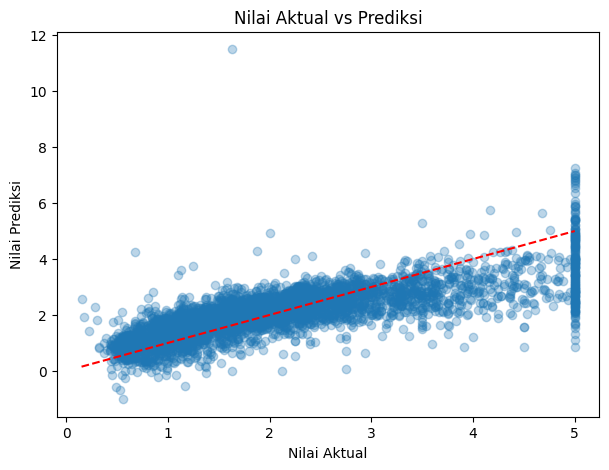

In [11]:
# Visualisasi 4: Nilai aktual vs prediksi
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_test_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title('Nilai Aktual vs Prediksi')
plt.xlabel('Nilai Aktual')
plt.ylabel('Nilai Prediksi')
plt.show()

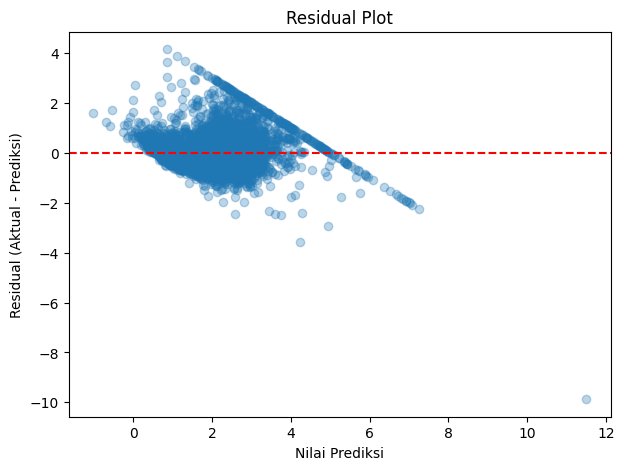

In [12]:
# Visualisasi 5: Residual plot
residuals = y_test - y_test_pred

plt.figure(figsize=(7, 5))

plt.scatter(y_test_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residual Plot')
plt.xlabel('Nilai Prediksi')
plt.ylabel('Residual (Aktual - Prediksi)')
plt.show()

**Interpretasi Visualisasi Evaluasi Model**

1. **Grafik Aktual vs Prediksi:** Sebagian besar titik mengikuti arah garis merah putus-putus, yang menunjukkan bahwa prediksi model cenderung mengikuti nilai aktual. Namun, penyebaran titik semakin besar pada nilai aktual yang tinggi. Model juga menghasilkan beberapa prediksi yang jauh dari nilai sebenarnya.

2. **Residual Plot:** Residual merupakan selisih antara nilai aktual dan nilai prediksi. Titik-titik tersebar di sekitar garis nol, tetapi penyebarannya tidak sepenuhnya acak dan terdapat beberapa residual ekstrem. Hal ini menunjukkan bahwa model masih memiliki kesalahan prediksi dan belum sepenuhnya menangkap pola data.

### A8. Analisis Performa

Model Linear Regression memperoleh R-squared sebesar 0,6126 pada data latih dan 0,5758 pada data uji. Nilai tersebut menunjukkan bahwa model mampu menjelaskan sekitar 57,58% variasi nilai target pada data uji.

Nilai MAE pada data latih sebesar 0,5286 dan pada data uji sebesar 0,5332. Sementara itu, RMSE pada data latih sebesar 0,7196 dan pada data uji sebesar 0,7456. Perbedaan metrik antara data latih dan data uji relatif kecil, sehingga tidak terdapat indikasi kuat terjadinya overfitting.

Fitur `MedInc` memiliki koefisien positif sebesar 0,4487 dan korelasi paling kuat dengan target, yaitu 0,69. Hal ini menunjukkan bahwa pendapatan median merupakan salah satu fitur yang berhubungan erat dengan nilai rumah.

Keterbatasan model terlihat dari nilai R-squared yang belum mendekati 1, penyebaran residual yang tidak sepenuhnya acak, serta adanya prediksi ekstrem. Selain itu, nilai target yang dibatasi pada 5,0 dapat memengaruhi kemampuan model memprediksi rumah dengan nilai tinggi.